In [1]:
# FloraVision

# Goal: Upload a flower image and
#  let the CNN predict whether it is a Daisy, Dandelion, Rose, Sunflower, or Tulip.

In [2]:
!pip install -q importlib-resources

In [3]:
# 1.important imports

import tensorflow as tf
import tensorflow_datasets as tfds
!pip install -q tensorflow-datasets
!rm -rf /root/tensorflow_datasets/tf_flowers
!pip install -q --upgrade tensorflow-datasets



from google.colab import files
from PIL import Image
from io import BytesIO
# files – Upload an image from your computer.
# Image – Open and process the uploaded image.
# BytesIO – Read uploaded image data directly from memory.




In [4]:


# 2. load flower dataset

(train_ds,val_ds,test_ds),info = tfds.load("tf_flowers",split=["train[:80%]","train[80%:90%]","train[90%:]"],as_supervised=True,with_info=True)

# fds.load() - Downloads and loads the flower dataset.

# "tf_flowers" - The name of our dataset.

# split - Divides the dataset into three portions.

# as_supervised=True - Returns images and their corresponding labels.

# with_info=True - Provides additional dataset information, such as category names and total image count.


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/tf_flowers/incomplete.83LQPC_3.0.1/tf_flowers-train.tfrecord-[0-9][0-9][0-…

Dataset tf_flowers downloaded and prepared to /root/tensorflow_datasets/tf_flowers/3.0.1. Subsequent calls will reuse this data.


In [5]:
class_names = info.features["label"].names

print("Flower Classes:", class_names)
print("Dataset Loaded Successfully!")


Flower Classes: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']
Dataset Loaded Successfully!


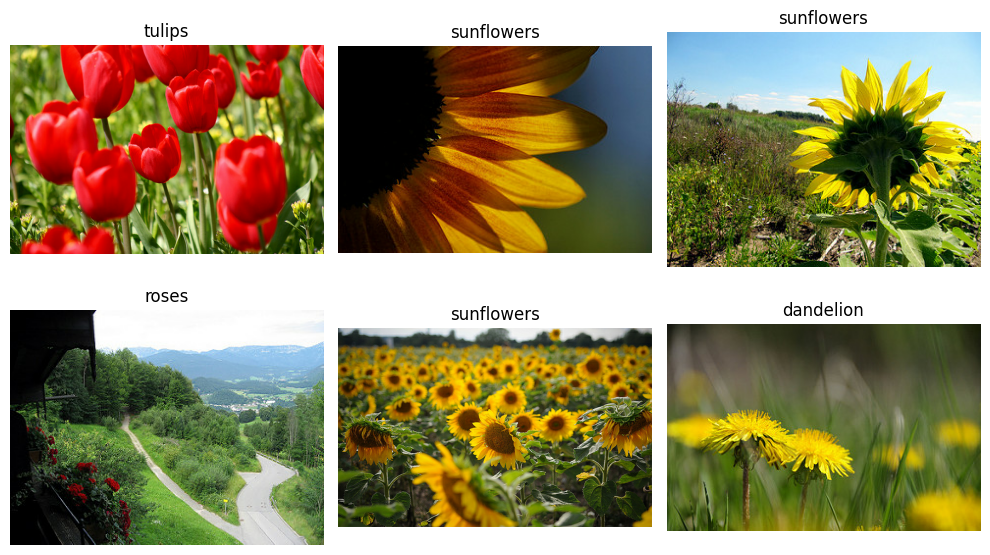

In [6]:
# 3. VISUALIZE FLOWER IMAGES
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for i, (image, label) in enumerate(train_ds.take(6)):
    plt.subplot(2, 3, i+1)
    plt.imshow(image)
    plt.title(class_names[label.numpy()])
    plt.axis("off")

plt.tight_layout()
plt.show()


# train_ds.take(6) – Takes six images.
# image – Actual flower photograph.
# label – Flower category number.
# enumerate() – Gives each image an index.

In [7]:
# 4. IMAGE PREPROCESSING
def preprocess(image, label):
    image = tf.image.resize(image, (128, 128))
    image = image / 255.0
    return image, label



In [8]:
train_ds = train_ds.map(preprocess).shuffle(1000).batch(32)
val_ds = val_ds.map(preprocess).batch(32)
test_ds = test_ds.map(preprocess).batch(32)


In [9]:
# 5. BUILD CNN MODEL
model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(128, 128, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2, 2),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2, 2),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation="relu"),

    tf.keras.layers.Dense(5, activation="softmax")
])



In [10]:
# 6. COMPILE THE MODEL
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [11]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,392,965 (28.20 MB)

 Trainable params: 7,392,965 (28.20 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# 7. TRAIN THE CNN MODEL
history = model.fit(train_ds,validation_data=val_ds,epochs=10)

Epoch 1/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 63s 626ms/step - accuracy: 0.4326 - loss: 1.4205 - val_accuracy: 0.5613 - val_loss: 1.1346
Epoch 2/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 52s 563ms/step - accuracy: 0.6073 - loss: 0.9938 - val_accuracy: 0.6185 - val_loss: 1.0068
Epoch 3/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 48s 525ms/step - accuracy: 0.7228 - loss: 0.7664 - val_accuracy: 0.6049 - val_loss: 1.0751
Epoch 4/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 55s 597ms/step - accuracy: 0.8212 - loss: 0.4931 - val_accuracy: 0.6567 - val_loss: 1.0238
Epoch 5/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 51s 554ms/step - accuracy: 0.9142 - loss: 0.2767 - val_accuracy: 0.6594 - val_loss: 1.1403
Epoch 6/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 83s 562ms/step - accuracy: 0.9622 - loss: 0.1451 - val_accuracy: 0.6403 - val_loss: 1.3217
Epoch 7/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 86s 598ms/step - accuracy: 0.9721 - loss: 0.1129 - val_accuracy: 0.6294 - val_loss: 1.4736
Epoch 8/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 53s 565ms/step - accuracy: 0.9796 - loss: 0.0827 - val_accu

In [14]:
# 8. EVALUATE THE MODEL
loss, accuracy = model.evaluate(test_ds)

print("Test Accuracy:", round(accuracy * 100, 2), "%")
print("Test Loss:", round(loss, 4))


12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 269ms/step - accuracy: 0.6839 - loss: 1.6717
Test Accuracy: 68.39 %
Test Loss: 1.6717


In [15]:
uploaded = files.upload()

file_name = next(iter(uploaded))

img = Image.open(BytesIO(uploaded[file_name])).convert("RGB")




Saving daisy.jpg to daisy.jpg


In [17]:
# 11. PREPARE IMAGE FOR PREDICTION
import numpy as np
img = img.resize((128, 128))

img_array = np.array(img) / 255.0

img_array = np.expand_dims(img_array, axis=0)



In [18]:
# 12. PREDICT THE FLOWER
prediction = model.predict(img_array)

index = np.argmax(prediction[0])

flower = class_names[index]

confidence = prediction[0][index] * 100




1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step


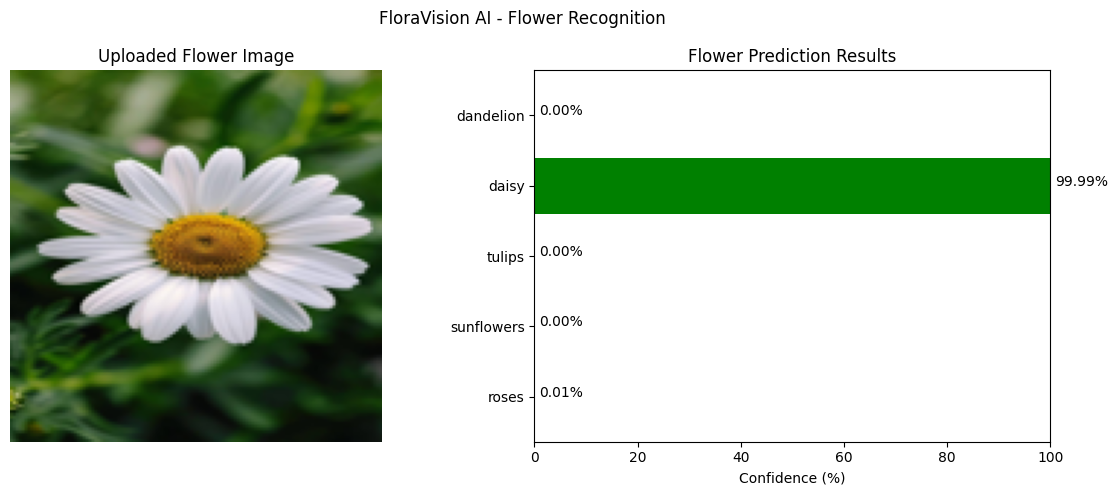

In [19]:
# 13. DISPLAY VISUAL PREDICTION DASHBOARD

scores = prediction[0] * 100

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Uploaded Image
ax[0].imshow(img)
ax[0].set_title("Uploaded Flower Image")
ax[0].axis("off")

# Probability Graph
colors = ["skyblue"] * 5
colors[index] = "green"

ax[1].barh(class_names, scores, color=colors)
ax[1].set_title("Flower Prediction Results")
ax[1].set_xlabel("Confidence (%)")
ax[1].set_xlim(0, 100)
ax[1].invert_yaxis()

for i, value in enumerate(scores):
    ax[1].text(value + 1, i, f"{value:.2f}%")

plt.suptitle("FloraVision AI - Flower Recognition")
plt.tight_layout()
plt.show()



In [20]:
# FINAL RESULT
print("==============================")
print(" FLORAVISION AI RESULT")
print("==============================")
print("Predicted Flower:", flower)
print("Confidence:", round(confidence, 2), "%")
print("==============================")

 FLORAVISION AI RESULT
Predicted Flower: daisy
Confidence: 99.99 %
